In [1]:
import xdem
import matplotlib.pyplot as plt
import geoutils as gu
from scipy import stats
import glob
from geoutils import raster
from SeBVel.seaso_amp import mask_geotiff,concatenate_geotiff

In [2]:
dataset = "IGE_non_filtered"

In [3]:
DEM_Alps = '/Users/charriel/Documents/Seasonality/Alps/metadata/DEM/Copernicus30m/DEM_30m_cropped_for_illumination.tif'

if dataset == "IGE_filtered":
    path_tiff = f'/Users/charriel/Documents/Seasonality/Alps/IGE_filtered/Weighted_median90/'
elif dataset == "IGE_non_filtered":
    path_tiff = f'/Users/charriel/Documents/Seasonality/Alps/IGE_non_filtered/Weighted_median90/'
elif dataset == "ITS_LIVE":
    path_tiff = f'/Users/charriel/Documents/Seasonality/Alps/ITS_LIVE/Weighted_median90/'

shapefile_mask = '/Users/charriel/Documents/Seasonality/Alps/metadata/crop_stable_areas_massif_without_mask_Diego.gpkg'
vexist = True

In [8]:
concatenate_geotiff(path_tiff,type_list=['phase', 'amplitude'],vexist=True)

/opt/homebrew/Cellar/micromamba/2.3.0/envs/SebVel/lib/python3.11/site-packages/geoutils/raster/multiraster.py:166: UserWarning: Some input Rasters have multiple bands, only their first band will be used.
  warnings.warn("Some input Rasters have multiple bands, only their first band will be used.")
/opt/homebrew/Cellar/micromamba/2.3.0/envs/SebVel/lib/python3.11/site-packages/geoutils/raster/raster.py:1822: UserWarning: Setting default nodata -99999 to mask non-finite values found in the array, as no nodata value was defined.
  warnings.warn(
/opt/homebrew/Cellar/micromamba/2.3.0/envs/SebVel/lib/python3.11/site-packages/geoutils/raster/raster.py:1822: UserWarning: Setting default nodata -99999 to mask non-finite values found in the array, as no nodata value was defined.
  warnings.warn(
/opt/homebrew/Cellar/micromamba/2.3.0/envs/SebVel/lib/python3.11/site-packages/geoutils/raster/raster.py:1822: UserWarning: Setting default nodata -99999 to mask non-finite values found in the array, as 

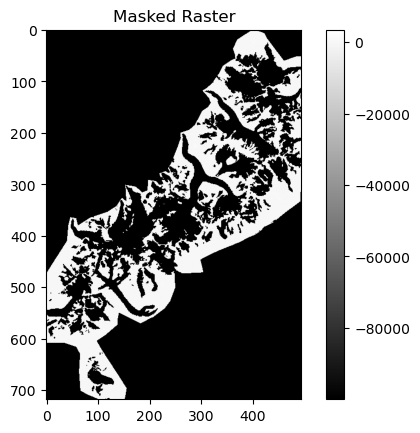

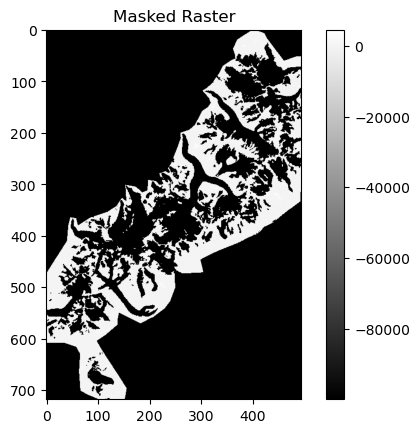

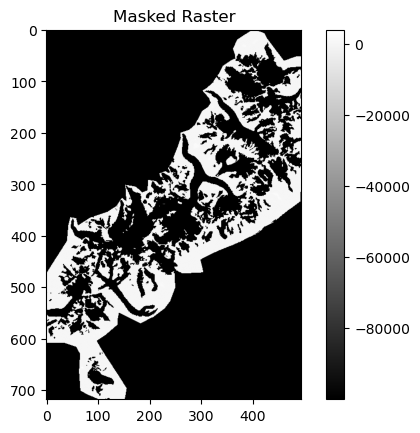

In [9]:
# mask_geotiff(path_tiff=path_tiff,shapefile_mask=shapefile_mask,var_list = ['amplitudex', 'amplitudey', 'amplitudev'])


#TO MASK AMPLITUDE ACCORDING TO A NEW SHAPFILE (comment or uncomment)

import geopandas as gpd
import rasterio.mask
import matplotlib.pyplot as plt
from shapely.geometry import mapping

# Define file paths
shapefile_path = '/Users/charriel/Documents/Seasonality/Alps/metadata/crop_stable_areas_massif_without_mask_Diego.gpkg'

var_list = ['amplitudex', 'amplitudey', 'amplitudev']
#var_list = ['amplitudex', 'amplitudey']

for variable in var_list:

    raster_path = f"{path_tiff}/{variable}.tif"  #change to x or y
    output_raster_path = f"{path_tiff}/{variable}_cropped_massif.tif"  #change to x or y

    # Read the shapefile
    shapefile = gpd.read_file(shapefile_path)
    # Remove empty geometries
    shapefile = shapefile[~shapefile.geometry.is_empty]

    if shapefile.empty:
        raise ValueError("The shapefile contains only empty geometries. Cannot proceed with masking.")

    # Convert geometries to GeoJSON-like format
    geometries = [mapping(geom) for geom in shapefile.geometry]

    # Read the raster file
    with rasterio.open(raster_path) as src:
        out_image, out_transform = rasterio.mask.mask(src, geometries, crop=True)
        out_meta = src.meta.copy()

    # Update metadata
    out_meta.update({"driver": "GTiff",
                     "height": out_image.shape[1],
                     "width": out_image.shape[2],
                     "transform": out_transform})

    # Save the masked raster
    with rasterio.open(output_raster_path, "w", **out_meta) as dest:
        dest.write(out_image)

    # Plot the masked raster
    masked_raster = out_image[0]  # Assuming the raster has only one band
    plt.imshow(masked_raster, cmap='gray')
    plt.colorbar()
    plt.title('Masked Raster')
    plt.show()


In [10]:
#TO READ THE GEOTIFF AMPLITUDES

amplitudex = f'{path_tiff}/amplitudex_cropped_massif.tif'
amplitudey = f'{path_tiff}/amplitudey_cropped_massif.tif'
amplitudev = f'{path_tiff}/amplitudev_cropped_massif.tif'

#load
amplitudex, dem_alps, amplitudey,amplitudev = gu.raster.load_multiple_rasters(
    [amplitudex, DEM_Alps, amplitudey,amplitudev], crop=True,
    ref_grid=0)

In [11]:
#COMPUTE ASPECT AND SLOPE
aspect = xdem.terrain.aspect(dem_alps)
slope = xdem.terrain.slope(dem_alps)
slope.set_mask(amplitudex.data.mask)

/opt/homebrew/Cellar/micromamba/2.3.0/envs/SebVel/lib/python3.11/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)
/var/folders/ct/zr9yz4l14g590fkxspmrbp0m0000gp/T/ipykernel_14466/1748507927.py:51: UserWarning: Warning: converting a masked element to nan.
  bin_averages[j, i] = np.nanmedian(bin_values)


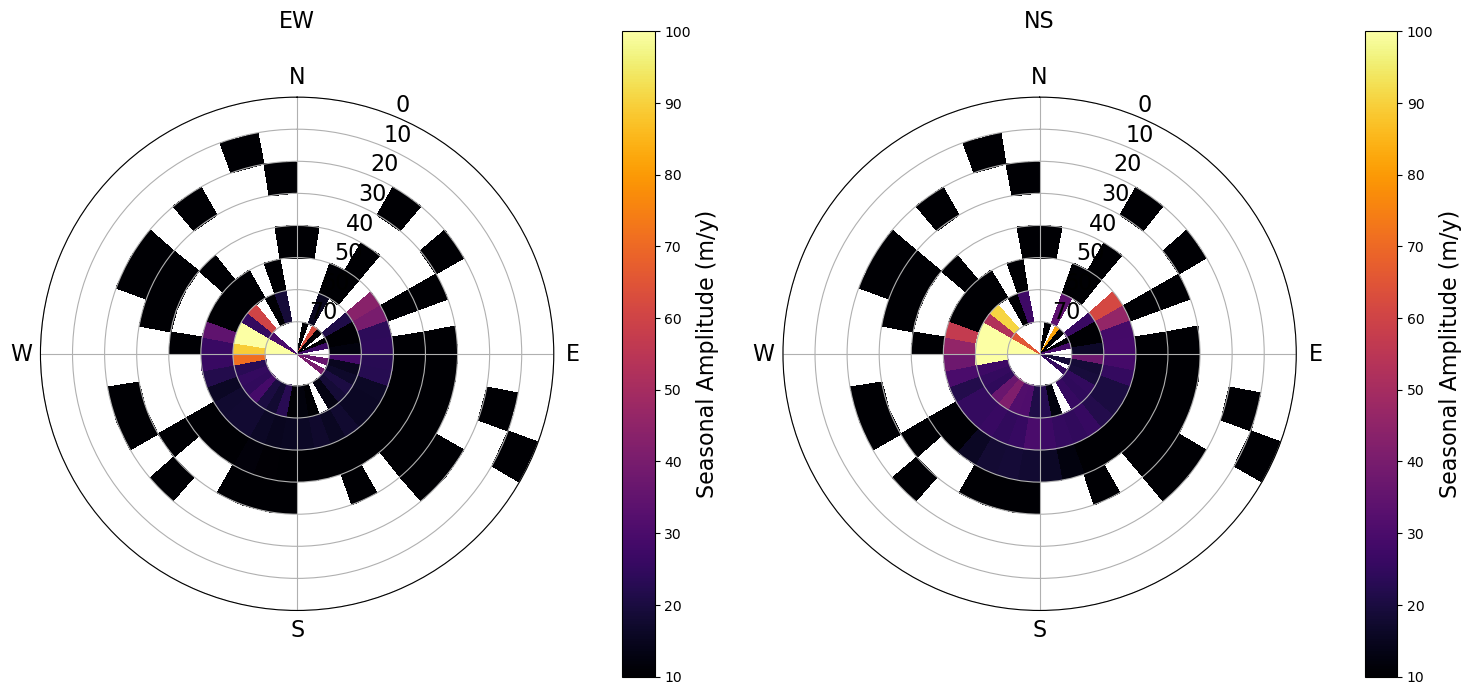

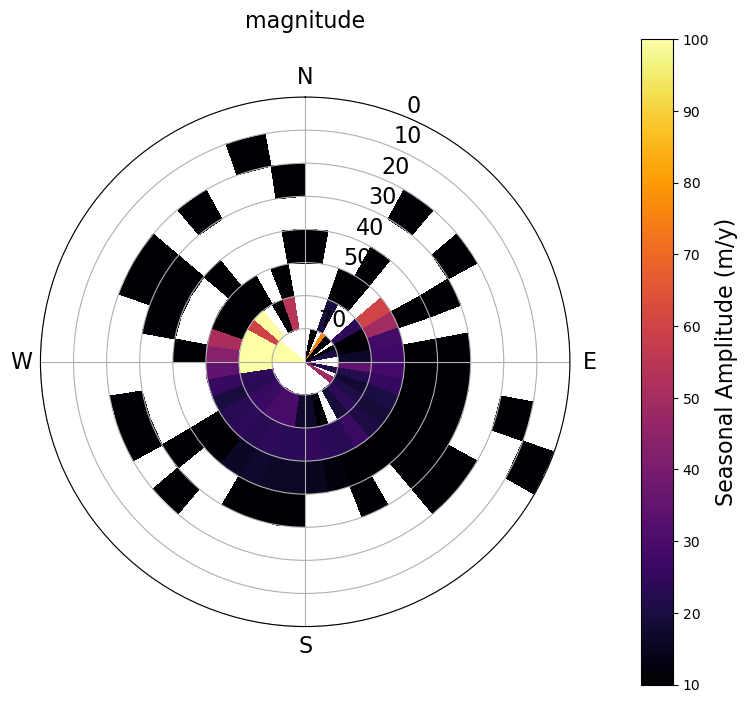

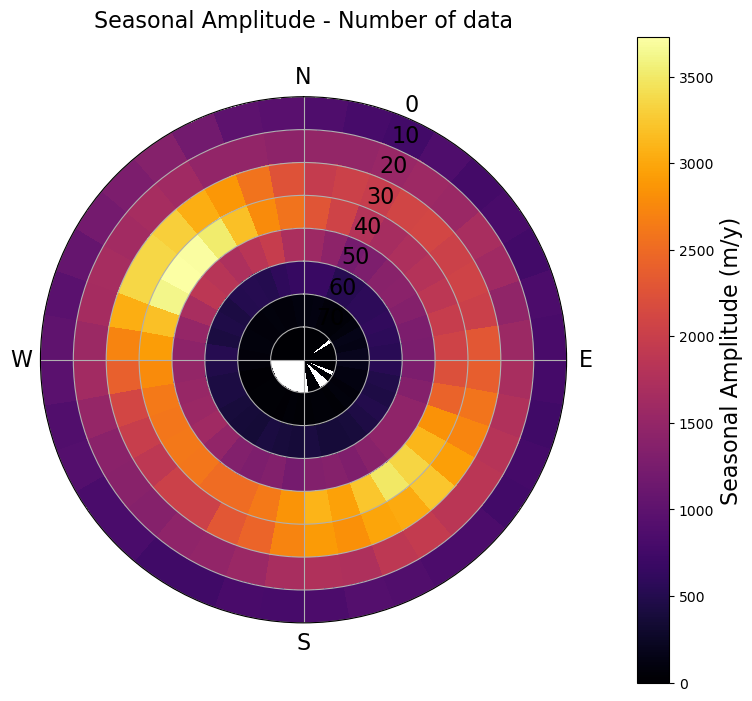

In [12]:
## POLAR PLOTS

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import colors  # Import LogNorm from matplotlib

# Example data, replace these with your actual slope gradient, aspect, and amplitude data
aspect_angles = aspect.data[aspect.data.mask == False]
slope_angles = slope.data[aspect.data.mask == False]
EW_amplitude = amplitudex.data[aspect.data.mask == False]  # Replace with your actual EW amplitude data
NS_amplitude = amplitudey.data[aspect.data.mask == False]  # Replace with your actual NS amplitude data
v_amplitude = amplitudev.data[aspect.data.mask == False]  # Replace with your actual NS amplitude data

vmin = 0.1  # Avoid zero for logarithmic scaling
criterion = 'median'

if criterion == 'median':
    if dataset == "IGE_filtered":
        vmax = 10
        vmin = 1

    elif dataset == "IGE_non_filtered":
        vmax = 100
        vmin=10
    elif dataset == "ITS_LIVE":
        vmax = 30
        vmin=5
elif criterion == 'mean':
    if dataset == "IGE_filtered":
        vmax = 5
        vmin = 0
    elif dataset == "IGE_non_filtered":vmax = 130

# Function to calculate average amplitude per 10x10 degree bin
def calculate_bin_averages(aspect_angles, slope_angles, amplitudes, criterion='mean'):
    bins_aspect = np.arange(0, 370, 10)
    bins_slope = np.arange(0, 90, 10)
    bin_averages = np.zeros((len(bins_slope) - 1, len(bins_aspect) - 1))
    bin_number_of_values = np.zeros((len(bins_slope) - 1, len(bins_aspect) - 1))

    for i in range(len(bins_aspect) - 1):
        for j in range(len(bins_slope) - 1):
            mask = ((aspect_angles >= bins_aspect[i]) & (aspect_angles < bins_aspect[i + 1]) &
                    (slope_angles >= bins_slope[j]) & (slope_angles < bins_slope[j + 1]))
            bin_values = amplitudes[mask]
            bin_number_of_value = len(bin_values)
            if len(bin_values) > 0:
                if criterion == 'mean':
                    bin_averages[j, i] = np.nanmean(bin_values)
                elif criterion == 'median':
                    bin_averages[j, i] = np.nanmedian(bin_values)
                elif criterion == 'std':
                    bin_averages[j, i] = np.std(bin_values)
                elif criterion == 'MAD':
                    bin_averages[j, i] = stats.median_abs_deviation(bin_values)
                elif criterion == '95':
                    bin_averages[j, i] = np.percentile(bin_values, 95)
                bin_number_of_values[j, i] = bin_number_of_value
            else:
                bin_averages[j, i] = np.nan  # Handle empty bins
                bin_number_of_values[j, i] = np.nan

    return bins_aspect, bins_slope, bin_averages, bin_number_of_values


# Function to create polar plot with bin averages
def create_polar_plot_with_bins(bin_averages, bins_aspect, bins_slope, title, color_map,vmin, vmax, subplot_position,
                                norm='normal', one_plot=False,label = 'Seasonal Amplitude (m/y)'):
    if not one_plot:
        ax = plt.subplot(1, 2, subplot_position, projection='polar')
    else:
        ax = plt.subplot(projection='polar')
    theta, r = np.meshgrid(np.deg2rad(bins_aspect), 80 - bins_slope)

    # Apply logarithmic scale using LogNorm
    if norm == 'log':
        norm = colors.LogNorm(vmin=1, vmax=vmax)
        c = ax.pcolormesh(theta, r, bin_averages, cmap=color_map, norm=norm, shading='auto')
    else:
        c = ax.pcolormesh(theta, r, bin_averages, cmap=color_map, vmin=vmin, vmax=vmax, shading='auto')
    ax.set_theta_direction(-1)
    ax.set_theta_zero_location('N')
    ax.set_title(title, fontsize=16, pad=50)
    plt.colorbar(c, ax=ax, pad=0.1, orientation='vertical').set_label(label, fontsize=16)
    r_labels = np.arange(0, 80, 10)  # Adjust step size as needed
    ax.set_yticks(80 - r_labels)  # Position ticks accordingly
    ax.set_yticklabels(r_labels, fontsize=16)  # Label them correctly
    ax.set_xticks(np.deg2rad([0, 90, 180, 270]))  # Set the custom angle ticks
    ax.set_xticklabels(['N', 'E', 'S', 'W'], fontsize=16)  # Label them as N, E, S, W

    # Position the y-tick labels more prominently at the top
    for label in ax.get_yticklabels():
        label.set_verticalalignment('bottom')


# Calculate bin averages
bins_aspect, bins_slope, EW_bin_averages, EW_bin_number_of_values = calculate_bin_averages(aspect_angles, slope_angles,
                                                                                           EW_amplitude,
                                                                                           criterion=criterion)
_, _, NS_bin_averages, NS_bin_number_of_values = calculate_bin_averages(aspect_angles, slope_angles, NS_amplitude,                                                                     criterion=criterion)

_, _, v_bin_averages, v_bin_number_of_values = calculate_bin_averages(aspect_angles, slope_angles, v_amplitude,                                                                     criterion=criterion)

# Plot configuration
fig = plt.figure(figsize=(15, 7))
# Plot EW Seasonal Amplitude with bin averages
create_polar_plot_with_bins(EW_bin_averages, bins_aspect, bins_slope, 'EW', 'inferno',vmin, vmax, 1)

# Plot NS Seasonal Amplitude with bin averages
create_polar_plot_with_bins(NS_bin_averages, bins_aspect, bins_slope, 'NS', 'inferno',vmin, vmax, 2)
plt.tight_layout()
fig.savefig(f"{path_tiff}/Polar_plot_amplitude_{criterion}.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Plot configuration
fig = plt.figure(figsize=(15, 7))
# Plot EW Seasonal Amplitude with bin averages
create_polar_plot_with_bins(v_bin_averages, bins_aspect, bins_slope, 'magnitude', 'inferno',vmin, vmax, 1)
plt.tight_layout()
plt.show()
plt.close()

fig = plt.figure(figsize=(15, 7))
# Plot EW Seasonal Amplitude with bin number of values
create_polar_plot_with_bins(EW_bin_number_of_values, bins_aspect, bins_slope, 'Seasonal Amplitude - Number of data',
                            'inferno',0, None, 1, norm=None)
plt.tight_layout()
fig.savefig(f"{path_tiff}/Polar_plot_number_of_values.png", dpi=300, bbox_inches='tight')
plt.show()

/opt/homebrew/Cellar/micromamba/2.3.0/envs/SebVel/lib/python3.11/site-packages/numpy/lib/function_base.py:4824: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


ValueError: output array is read-only

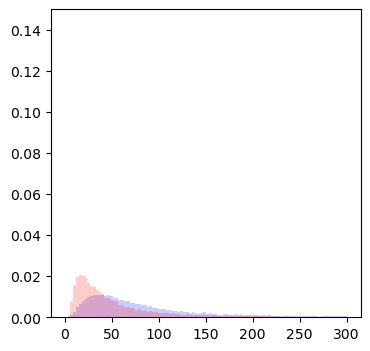

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

# Define aspect angle ranges for each quadrant
quadrants = {
    "N1": (0, 90),
    "S": (90, 270),
    "N2": (270, 360)
}
#vmax = 200
#ymax = 0.04
if dataset == "IGE_non_filtered":
    vmax = 300
    ymax = 0.15
elif dataset == "IGE_filtered":
    # vmax = 50
    # ymax = 0.3
    vmax = 300
    ymax = 0.15
elif dataset == "ITS_LIVE":
    vmax = 100
    ymax = 0.1

def plot_hist(data_amplitude, label='EW'):
    # Create figure
    fig, ax = plt.subplots(figsize=(4, 4))

    data_list = []
    # Plot histogram with PDF and median for each quadrant
    for quadrant, (low, high) in quadrants.items():
        mask = (aspect_angles >= low) & (aspect_angles < high)
        data_list.append(data_amplitude[mask])

    if len(data_list) > 0:
        # Plot histogram
        bins_number = 100
        ax.hist(np.ma.concatenate([data_list[0], data_list[2]]), bins=bins_number, density=True,
                alpha=0.2, color='b', range=(0, vmax), label='North')
        ax.hist(data_list[1], bins=bins_number, density=True, alpha=0.2, color='r',
                range=(0, vmax), label='South')

        ax.set_ylim(0, ymax)

        # Compute statistics for the two groups
        mus, stds = np.mean(data_list[1]), np.std(data_list[1])
        p50s, p90s = np.percentile(data_list[1],50), np.percentile(data_list[1],90)

        mun, stdn = np.mean(np.ma.concatenate([data_list[0], data_list[2]])), np.std(
            np.ma.concatenate([data_list[0], data_list[2]]))
        p50n, p90n = np.percentile(np.ma.concatenate([data_list[0], data_list[2]]),50), np.percentile(np.ma.concatenate([data_list[0], data_list[2]]),90)


        # Prepare statistics text
        stats_text = f"South: 50% {p50s:.1f} m/y ; 90% {p90s:.1f} m/y\n North: 50% {p50n:.1f} m/y ; 90% {p90n:.1f} m/y"

        # Place the text below the graph using fig.text
        fig.text(0.6, -0.1, stats_text, ha='center', fontsize=10,
                 bbox=dict(facecolor='white', alpha=0.8))

        ax.set_xlabel(f"{label} Amplitude [m/y]", fontsize=10)
        ax.legend(fontsize=10)
        ax.set_ylabel("Density")

    plt.tight_layout()
    fig.savefig(f"{path_tiff}/Hist_{label}_amplitude_NS.png", dpi=300, bbox_inches='tight')
    plt.show()


# plot_hist(vv_amplitude, label='vv')
plot_hist(EW_amplitude, label='EW')
plot_hist(NS_amplitude, label='NS')


In [22]:
## POLAR PLOTS

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import colors  # Import LogNorm from matplotlib

# Example data, replace these with your actual slope gradient, aspect, and amplitude data
aspect_angles = aspect.data[aspect.data.mask == False]
slope_angles = slope.data[aspect.data.mask == False]
EW_amplitude = amplitudex.data[aspect.data.mask == False]  # Replace with your actual EW amplitude data
NS_amplitude = amplitudey.data[aspect.data.mask == False]  # Replace with your actual NS amplitude data
vmax = 3
vmin = 0.1  # Avoid zero for logarithmic scaling
if dataset == "IGE_filtered":vmax = 10
elif dataset == "IGE_non_filtered":vmax = 100
criterion = "median"

# Function to calculate average amplitude per 10x10 degree bin
def calculate_bin_averages(aspect_angles, slope_angles, amplitudes, criterion='mean'):
    bins_aspect = np.arange(0, 370, 90)
    bins_slope = np.arange(0, 120, 30)
    bin_averages = np.zeros((len(bins_slope) - 1, len(bins_aspect) - 1))
    bin_number_of_values = np.zeros((len(bins_slope) - 1, len(bins_aspect) - 1))

    for i in range(len(bins_aspect) - 1):
        for j in range(len(bins_slope) - 1):
            mask = ((aspect_angles >= bins_aspect[i]) & (aspect_angles < bins_aspect[i + 1]) &
                    (slope_angles >= bins_slope[j]) & (slope_angles < bins_slope[j + 1]))
            bin_values = amplitudes[mask]
            bin_number_of_value = len(bin_values)
            if len(bin_values) > 0:
                if criterion == 'mean':
                    bin_averages[j, i] = np.nanmean(bin_values)
                elif criterion == 'median':
                    bin_averages[j, i] = np.nanmedian(bin_values)
                elif criterion == 'std':
                    bin_averages[j, i] = np.std(bin_values)
                elif criterion == 'MAD':
                    bin_averages[j, i] = stats.median_abs_deviation(bin_values)
                elif criterion == '90':
                    bin_averages[j, i] = np.percentile(bin_values, 90)
                bin_number_of_values[j, i] = bin_number_of_value
            else:
                bin_averages[j, i] = np.nan  # Handle empty bins
                bin_number_of_values[j, i] = np.nan

    return bins_aspect, bins_slope, bin_averages, bin_number_of_values


# Function to create polar plot with bin averages
def create_polar_plot_with_bins(bin_averages, bins_aspect, bins_slope, title, color_map, vmax, subplot_position,
                                norm='normal', one_plot=False):
    if not one_plot:
        ax = plt.subplot(1, 2, subplot_position, projection='polar')
    else:
        ax = plt.subplot(projection='polar')
    theta, r = np.meshgrid(np.deg2rad(bins_aspect), 90 - bins_slope)

    # Apply logarithmic scale using LogNorm
    if norm == 'log':
        norm = colors.LogNorm(vmin=1, vmax=vmax)
        c = ax.pcolormesh(theta, r, bin_averages, cmap=color_map, norm=norm, shading='auto')
    else:
        c = ax.pcolormesh(theta, r, bin_averages, cmap=color_map, vmin=0, vmax=vmax, shading='auto')
    ax.set_theta_direction(-1)
    ax.set_theta_zero_location('N')
    ax.set_title(title, fontsize=16, pad=50)
    plt.colorbar(c, ax=ax, pad=0.1, orientation='vertical').set_label('Seasonal Amplitude (m/y)', fontsize=16)
    r_labels = np.arange(0, 90, 30)  # Adjust step size as needed
    ax.set_yticks(80 - r_labels)  # Position ticks accordingly
    ax.set_yticklabels(r_labels, fontsize=16)  # Label them correctly
    ax.set_xticks(np.deg2rad([0, 90, 180, 270]))  # Set the custom angle ticks
    ax.set_xticklabels(['N', 'E', 'S', 'W'], fontsize=16)  # Label them as N, E, S, W

    # Position the y-tick labels more prominently at the top
    for label in ax.get_yticklabels():
        label.set_verticalalignment('bottom')


# Calculate bin averages
bins_aspect, bins_slope, EW_bin_averages, EW_bin_number_of_values = calculate_bin_averages(aspect_angles, slope_angles,
                                                                                           EW_amplitude,
                                                                                           criterion=criterion)
_, _, NS_bin_averages, NS_bin_number_of_values = calculate_bin_averages(aspect_angles, slope_angles, NS_amplitude,
                                                                        criterion=criterion)
if vexist:_, _, v_bin_averages, v_bin_number_of_values = calculate_bin_averages(aspect_angles, slope_angles, v_amplitude,
                                                                        criterion=criterion)

# Plot configuration
fig = plt.figure(figsize=(15, 7))
# Plot EW Seasonal Amplitude with bin averages
create_polar_plot_with_bins(EW_bin_averages, bins_aspect, bins_slope, 'EW', 'inferno', vmax, 1)

# Plot NS Seasonal Amplitude with bin averages
create_polar_plot_with_bins(NS_bin_averages, bins_aspect, bins_slope, 'NS', 'inferno', vmax, 2)
plt.tight_layout()
fig.savefig(f"{path_tiff}/Polar_plot_amplitude_{criterion}_4quadrant.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Plot configuration
fig = plt.figure(figsize=(15, 7))
# Plot EW Seasonal Amplitude with bin averages
create_polar_plot_with_bins(v_bin_averages, bins_aspect, bins_slope, 'magnitude', 'inferno', vmax, 1)
plt.tight_layout()
fig.savefig(f"{path_tiff}/Polar_plot_amplitude_{criterion}_4quadrant.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close()

fig = plt.figure(figsize=(15, 7))
# Plot EW Seasonal Amplitude with bin number of values
create_polar_plot_with_bins(EW_bin_number_of_values, bins_aspect, bins_slope, 'EW Seasonal Amplitude - Number of data',
                            'inferno', 5000, 1, norm='log')

# Plot NS Seasonal Amplitude with bin number of values
create_polar_plot_with_bins(NS_bin_number_of_values, bins_aspect, bins_slope, 'NS Seasonal Amplitude - Number of data',
                            'inferno', 5000, 2, norm='log')
plt.tight_layout()
fig.savefig(f"{path_tiff}/Polar_plot_number_of_values_shorter.png", dpi=300, bbox_inches='tight')
plt.show()

/opt/homebrew/Cellar/micromamba/2.3.0/envs/SebVel/lib/python3.11/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


NameError: name 'vexist' is not defined

In [ ]:

import pandas as pd

path_save = "/Users/charriel/Documents/Seasonality/Alps/shadows_projection/interpolation_to_glacier_areas_new_results"
save = False

EW_bin_averages_df = pd.DataFrame(EW_bin_averages)
# Assigning index and column values
EW_bin_averages_df.index = np.arange(30, 120, 30)  # Set index values
EW_bin_averages_df.columns = np.arange(90, 370, 90)  # Set column names

# Assigning names to index and columns
EW_bin_averages_df.index.name = "Slope Bins"  # Name for the index
EW_bin_averages_df.columns.name = "Aspect Bins"  # Name for the columns
if save: EW_bin_averages_df.to_csv(
    f'{path_save}/EW_bins_averages_{criterion}.csv')

NS_bin_averages_df = pd.DataFrame(NS_bin_averages)
# Assigning index and column values
NS_bin_averages_df.index = np.arange(30, 120, 30)  # Set index values
NS_bin_averages_df.columns = np.arange(90, 370, 90)  # Set column names
# Assigning names to index and columns
NS_bin_averages_df.index.name = "Slope Bins"  # Name for the index
NS_bin_averages_df.columns.name = "Aspect Bins"  # Name for the columns
if save: NS_bin_averages_df.to_csv(
    f'{path_save}/NS_bins_averages_{criterion}.csv')

NS_bin_averages_df = pd.DataFrame(v_bin_averages)
# Assigning index and column values
NS_bin_averages_df.index = np.arange(30, 120, 30)  # Set index values
NS_bin_averages_df.columns = np.arange(90, 370, 90)  # Set column names
# Assigning names to index and columns
NS_bin_averages_df.index.name = "Slope Bins"  # Name for the index
NS_bin_averages_df.columns.name = "Aspect Bins"  # Name for the columns
if save: NS_bin_averages_df.to_csv(
    f'{path_save}/vv_bins_averages_{criterion}.csv')